<a href="https://colab.research.google.com/github/Joyitacodes/Joyitacodes/blob/main/LSTM_dna_sequence_generation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# DNA Sequence Generation using an LSTM (HBB gene / Sickle Cell Disease)

# GOAL:
#   Demonstrate that an LSTM can be used for generative modelling of biological  sequences (DNA), not just text. DNA is treated like character-level text
#   with a 4-letter vocabulary: A, C, G, T.
#<br>

# DATA :
#   - "normal" : real human HBB mRNA reference sequence, NCBI accession
#                NM_000518, downloaded via Biopython's Entrez.
#   - "sickle" : SYNTHETIC. Created by editing the normal sequence at codon 6
#                (GAG -> GTG, Glu -> Val), the known HbS point mutation.
#   No real patient data is used. The dataset is tiny (~600 bases per
#   sequence), so results are a proof of concept, not a clinical model.
# <br>

# METHOD:
#   1. Slide a window of SEQ_LEN bases over each sequence; predict the next base.
#   2. Train a single-layer LSTM (one-hot input -> softmax over A/C/G/T).
#   3. Generate new sequences base-by-base with temperature sampling.
#   4. Evaluate: k-mer statistics, GC content, copying from training data,
#      and similarity to the sickle/normal codon-6 motifs.
# <br>

# KNOWN LIMITATIONS:
#   - Overlapping windows from one gene => very little independent data.
#   - Validation accuracy is expected to stay near chance (0.25): the model
#     memorizes rather than generalizes.
#   - Generated sequences are not biologically validated.


In [3]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 74.5 MB/s  0:00:00


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from itertools import product
from Bio import Entrez, SeqIO
from tensorflow.keras import layers, models, callbacks
import tensorflow as tf

np.random.seed(42)
tf.random.set_seed(42)


# 1. Data: HBB mRNA reference + sickle variant (codon 6 GAG -> GTG)

In [6]:

Entrez.email = "joyita.nandan@msds.christuniversity.in"
rec = SeqIO.read(Entrez.efetch(db="nucleotide", id="NM_000518",
                               rettype="fasta", retmode="text"), "fasta")
normal = str(rec.seq).upper()
NORMAL_MOTIF, SICKLE_MOTIF = "CCTGAGGAG", "CCTGTGGAG"   # codon 6 region
i = normal.find(NORMAL_MOTIF)
assert i != -1, "codon-6 motif not found"
sickle = normal[:i] + SICKLE_MOTIF + normal[i + len(NORMAL_MOTIF):]  # SYNTHETIC
print(f"Sequence length: {len(normal)} | codon-6 motif at index {i}")

chars = "ACGT"
c2i = {c: k for k, c in enumerate(chars)}
SEQ_LEN = 40

def make_windows(seq):
    X, y = [], []
    for s in range(len(seq) - SEQ_LEN):
        X.append([c2i[c] for c in seq[s:s + SEQ_LEN]])
        y.append(c2i[seq[s + SEQ_LEN]])
    return np.array(X), np.array(y)

Xn, yn = make_windows(normal)
Xs, ys = make_windows(sickle)
X = np.eye(4)[np.concatenate([Xn, Xs])]          # one-hot -> (N, 40, 4)
y = np.concatenate([yn, ys])

# Positional split (not random) so validation windows are not near-duplicates
# of training windows. Last 20% of each sequence is held out.
cut = int(0.8 * len(Xn))
tr = np.r_[0:cut, len(Xn):len(Xn) + cut]
va = np.r_[cut:len(Xn), len(Xn) + cut:len(X)]

# Baselines for context
chance = 0.25
majority = np.bincount(y[va]).max() / len(va)
print(f"Baselines on val set -> chance: {chance:.2f} | majority-class: {majority:.2f}")

Sequence length: 628 | codon-6 motif at index 65
Baselines on val set -> chance: 0.25 | majority-class: 0.35


# 2. MODEL

Epoch 1/60
30/30 - 3s - 97ms/step - accuracy: 0.2926 - loss: 1.3767 - val_accuracy: 0.1695 - val_loss: 1.4190
Epoch 2/60
30/30 - 0s - 10ms/step - accuracy: 0.3191 - loss: 1.3626 - val_accuracy: 0.1695 - val_loss: 1.4395
Epoch 3/60
30/30 - 0s - 10ms/step - accuracy: 0.3596 - loss: 1.3485 - val_accuracy: 0.1949 - val_loss: 1.4439
Epoch 4/60
30/30 - 0s - 11ms/step - accuracy: 0.3713 - loss: 1.3383 - val_accuracy: 0.2034 - val_loss: 1.4363
Epoch 5/60
30/30 - 0s - 10ms/step - accuracy: 0.3872 - loss: 1.3252 - val_accuracy: 0.1780 - val_loss: 1.4561
Epoch 6/60
30/30 - 0s - 10ms/step - accuracy: 0.3904 - loss: 1.3181 - val_accuracy: 0.1949 - val_loss: 1.4651
Epoch 7/60
30/30 - 0s - 10ms/step - accuracy: 0.3968 - loss: 1.3034 - val_accuracy: 0.1780 - val_loss: 1.4371
Epoch 8/60
30/30 - 0s - 10ms/step - accuracy: 0.3840 - loss: 1.3039 - val_accuracy: 0.1949 - val_loss: 1.5225
Epoch 9/60
30/30 - 0s - 10ms/step - accuracy: 0.4021 - loss: 1.2920 - val_accuracy: 0.1864 - val_loss: 1.5843


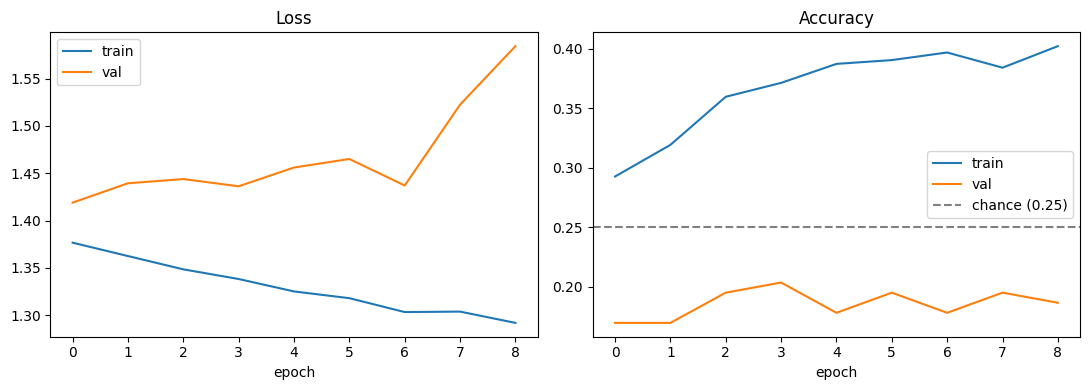

In [7]:
model = models.Sequential([
    layers.Input((SEQ_LEN, 4)),
    layers.LSTM(128),
    layers.Dropout(0.3),
    layers.Dense(4, activation="softmax"),
])
model.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])

early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                     restore_best_weights=True)
history = model.fit(X[tr], y[tr], validation_data=(X[va], y[va]),
                    epochs=60, batch_size=32, callbacks=[early_stop], verbose=2)

# Training curves: a widening train/val gap = overfitting
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].axhline(chance, ls="--", c="gray", label="chance (0.25)")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()


# 3. GENERATION

In [11]:
def sample(probs, temp):
    p = np.log(probs + 1e-9) / temp
    p = np.exp(p) / np.exp(p).sum()
    return np.random.choice(4, p=p)

def generate(seed, length=200, temp=0.8):
    out = list(seed)
    for _ in range(length):
        x = np.eye(4)[[c2i[c] for c in out[-SEQ_LEN:]]][None]
        probs = model(x, training=False).numpy()[0]
        out.append(chars[sample(probs, temp)])
    return "".join(out)

# 4. EVALUATION

In [9]:
def kmer_freq(s, k):
    c = Counter(s[j:j + k] for j in range(len(s) - k + 1))
    n = max(1, len(s) - k + 1)
    return np.array([c["".join(m)] for m in product(chars, repeat=k)]) / n

def gc_content(s):
    return (s.count("G") + s.count("C")) / len(s)

def min_mismatches(seq, motif):
    """Smallest Hamming distance between motif and any window of seq."""
    L = len(motif)
    return min(sum(a != b for a, b in zip(seq[j:j + L], motif))
               for j in range(len(seq) - L + 1))

train_text = normal + sickle
rows, all_seqs = [], []
for temp in [0.5, 0.8, 1.0, 1.2]:
    for n in range(3):                                   # 3 sequences per temp
        g = generate(normal[:SEQ_LEN], length=200, temp=temp)
        all_seqs.append((f"gen_T{temp}_{n}", g))
        rows.append({
            "temp": temp,
            "3mer_corr": np.corrcoef(kmer_freq(g, 3), kmer_freq(normal, 3))[0, 1],
            "4mer_corr": np.corrcoef(kmer_freq(g, 4), kmer_freq(normal, 4))[0, 1],
            "GC": gc_content(g),
            "copied_frac": np.mean([g[j:j + SEQ_LEN] in train_text
                                    for j in range(len(g) - SEQ_LEN)]),
            "HbS_mismatch": min_mismatches(g, SICKLE_MOTIF),
            "normal_mismatch": min_mismatches(g, NORMAL_MOTIF),
        })

results = pd.DataFrame(rows).groupby("temp").mean().round(3)
print(f"\nReference GC content (normal HBB): {gc_content(normal):.3f}")
print("Mean metrics per temperature (mismatch = 0 means exact motif found):")
print(results)

# Save generated sequences for the repo
with open("generated_sequences.fasta", "w") as f:
    for name, s in all_seqs:
        f.write(f">{name}\n{s}\n")


Reference GC content (normal HBB): 0.513
Mean metrics per temperature (mismatch = 0 means exact motif found):
      3mer_corr  4mer_corr     GC  copied_frac  HbS_mismatch  normal_mismatch
temp                                                                         
0.5       0.430      0.284  0.529        0.007         2.333            3.000
0.8       0.221      0.157  0.518        0.008         2.333            2.000
1.0       0.201      0.114  0.531        0.010         2.667            2.667
1.2       0.444      0.265  0.526        0.005         2.333            3.000


In [12]:
# Baseline: how many mismatches does a RANDOM sequence give?
def random_seq(n=240):
    return "".join(np.random.choice(list(chars), n))

base_hbs = np.mean([min_mismatches(random_seq(), SICKLE_MOTIF) for _ in range(200)])
base_nor = np.mean([min_mismatches(random_seq(), NORMAL_MOTIF) for _ in range(200)])
print(f"Random-sequence baseline -> HbS mismatch: {base_hbs:.2f} | normal mismatch: {base_nor:.2f}")

# Baseline: does the LSTM beat a simple 4-mer Markov chain on val data?
k = 4
counts = {}
for seq in (normal[:int(0.8*len(normal))], sickle[:int(0.8*len(sickle))]):
    for j in range(len(seq) - k):
        counts.setdefault(seq[j:j+k], Counter())[seq[j+k]] += 1
hits = tot = 0
for seq in (normal[int(0.8*len(normal)):], sickle[int(0.8*len(sickle)):]):
    for j in range(len(seq) - k):
        ctx = seq[j:j+k]
        if ctx in counts:
            hits += counts[ctx].most_common(1)[0][0] == seq[j+k]; tot += 1
print(f"Markov-4 val accuracy: {hits/max(tot,1):.3f} (on {tot} contexts seen in training)")

Random-sequence baseline -> HbS mismatch: 2.77 | normal mismatch: 2.77
Markov-4 val accuracy: 0.298 (on 188 contexts seen in training)


## Results & Discussion

Two training runs were compared on the same data (HBB mRNA reference, NM_000518,
plus a synthetic sickle variant with the codon-6 GAG->GTG edit).

| Run | Train acc | Val acc | Outcome |
|---|---|---|---|
| 60 epochs, no early stopping | ~0.91-0.95 | ~0.22-0.26 | Memorizes the training windows |
| Early stopping (best val loss) | ~0.40 | ~0.17-0.20 | Stops at epoch 1 weights, barely trained |

Validation baselines: chance = 0.25, majority-class = 0.35. Validation accuracy
in both runs is at or below these baselines, and validation loss never beats a
uniform guess (ln 4 ~ 1.386). The held-out region (last 20% of the sequence) also
has a different base composition from the training region, which makes the
split a hard test.

Generated sequences (4 temperatures x 3 sequences, 200 bases each) have GC
content of 0.52-0.53 (reference: 0.513) but 3-mer correlation of only
0.20-0.44, and the closest match to the codon-6 motif has 2-3 mismatches,
about what random sequence gives (see baseline output). The model does not learn the
difference between normal and sickle HBB.

**Baselines.** A random-sequence baseline gives an average closest-motif
mismatch of 2.77 (for both HbS and normal 9-mers), the same as the LSTM's
2.0-3.0, so the generated sequences are no closer to the codon-6 motif than
random ones. A 4-base Markov chain trained on the same split reaches 0.298
validation accuracy (188 contexts seen in training), above the LSTM's
0.17-0.20 but statistically close to chance (0.25) and below the majority-class
baseline (0.35). A simple model matches or beats the LSTM, which confirms the
bottleneck is data quantity, not model choice.


**Takeaway:** an LSTM can generate DNA-like sequences, but a ~600-base gene plus
one synthetic edit contains too little independent information to learn from.
Meaningful generalization would need many real HBB sequences (ClinVar, 1000
Genomes, or HBB orthologs from other species).